# Week 3 Task: Unsupervised Learning and Clustering Analysis

**Project Title:** Customer Segmentation Using K-Means Clustering

**Dataset:** Mall Customer Segmentation Dataset

**Algorithm:** K-Means Clustering

**Programming Language:** Python

**Platform:** Google Colab

**Libraries:** Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn

In [ ]:
# Importing required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
import os

# Check uploaded files
print(os.listdir('/content'))

['.config', '.ipynb_checkpoints', 'mall customers.csv.zip', 'sample_data']


In [ ]:
import os

print(os.listdir('/content'))

['.config', '.ipynb_checkpoints', 'mall customers.csv', 'sample_data']


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving mall customers.csv.zip to mall customers.csv.zip


In [ ]:
import pandas as pd

filename = list(uploaded.keys())[0]

df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [ ]:
# Display dataset dimensions
print("Dataset Shape:", df.shape)

# Display dataset information
print("\nDataset Information:")
df.info()

Dataset Shape: (200, 5)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [ ]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,1
1,2,Male,21,15,81,1
2,3,Female,20,16,6,0
3,4,Female,23,16,77,1
4,5,Female,31,17,40,1


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
 5   Cluster                 200 non-null    int32 
dtypes: int32(1), int64(4), object(1)
memory usage: 8.7+ KB


In [ ]:
# Statistical summary of numerical columns
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [ ]:
# Display column names
print("Dataset Columns:")
print(df.columns.tolist())

Dataset Columns:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']


In [ ]:
# Gender distribution

print("Gender Distribution:")
print(df['Gender'].value_counts())

# Gender percentage
print("\nGender Percentage:")
print(df['Gender'].value_counts(normalize=True) * 100)

Gender Distribution:
Gender
Female    112
Male       88
Name: count, dtype: int64

Gender Percentage:
Gender
Female    56.0
Male      44.0
Name: proportion, dtype: float64


In [ ]:
# Calculate average customer details

print("Average Age:", df['Age'].mean())
print("Average Annual Income:", df['Annual Income (k$)'].mean())
print("Average Spending Score:", df['Spending Score (1-100)'].mean())

Average Age: 38.85
Average Annual Income: 60.56
Average Spending Score: 50.2


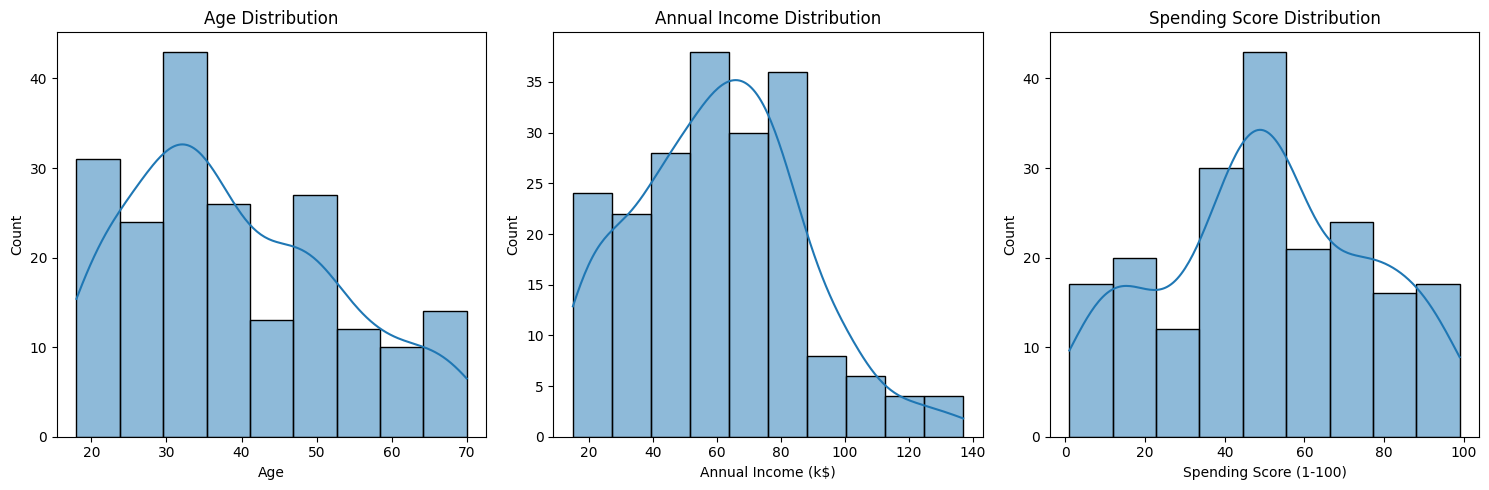

In [ ]:
# Distribution of customer attributes

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
sns.histplot(df['Age'], kde=True)
plt.title('Age Distribution')

plt.subplot(1, 3, 2)
sns.histplot(df['Annual Income (k$)'], kde=True)
plt.title('Annual Income Distribution')

plt.subplot(1, 3, 3)
sns.histplot(df['Spending Score (1-100)'], kde=True)
plt.title('Spending Score Distribution')

plt.tight_layout()
plt.show()

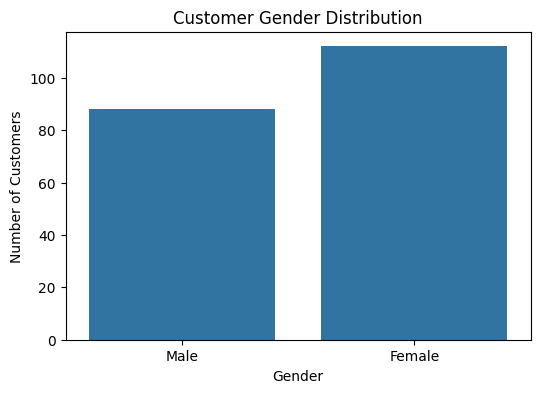

In [ ]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x='Gender')

plt.title('Customer Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Number of Customers')

plt.show()

In [ ]:
# Check missing values in each column

print("Missing Values:")
print(df.isnull().sum())

# Calculate missing value percentage
print("\nMissing Value Percentage:")
print((df.isnull().sum() / len(df)) * 100)

Missing Values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Missing Value Percentage:
CustomerID                0.0
Gender                    0.0
Age                       0.0
Annual Income (k$)        0.0
Spending Score (1-100)    0.0
dtype: float64


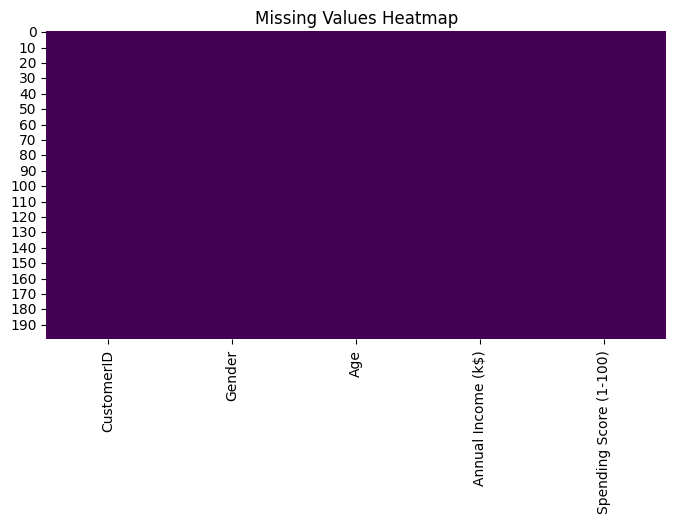

In [ ]:
# Visualize missing values

plt.figure(figsize=(8, 4))

sns.heatmap(df.isnull(), cbar=False, cmap='viridis')

plt.title('Missing Values Heatmap')
plt.show()

In [ ]:
# Check duplicate records

print("Total Duplicate Rows:", df.duplicated().sum())

Total Duplicate Rows: 0


In [ ]:
# Remove duplicate records if present

df = df.drop_duplicates()

print("Dataset Shape After Removing Duplicates:", df.shape)
print("Remaining Duplicate Rows:", df.duplicated().sum())

Dataset Shape After Removing Duplicates: (200, 5)
Remaining Duplicate Rows: 0


In [ ]:
# Final dataset quality check

print("Total Records:", len(df))
print("Total Columns:", len(df.columns))
print("Total Missing Values:", df.isnull().sum().sum())
print("Total Duplicate Rows:", df.duplicated().sum())

Total Records: 200
Total Columns: 5
Total Missing Values: 0
Total Duplicate Rows: 0


In [ ]:
# Feature selection

X = df[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']]

# Display selected features
print("Selected Features:")
print(X.head())

print("\nFeature Shape:", X.shape)

Selected Features:
   Age  Annual Income (k$)  Spending Score (1-100)
0   19                  15                      39
1   21                  15                      81
2   20                  16                       6
3   23                  16                      77
4   31                  17                      40

Feature Shape: (200, 3)


In [ ]:
# Statistical summary of selected features

print("Selected Feature Statistics:")
display(X.describe())

Selected Feature Statistics:


,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000
mean,38.850000,60.560000,50.200000
std,13.969007,26.264721,25.823522
min,18.000000,15.000000,1.000000
25%,28.750000,41.500000,34.750000
50%,36.000000,61.500000,50.000000
75%,49.000000,78.000000,73.000000
max,70.000000,137.000000,99.000000


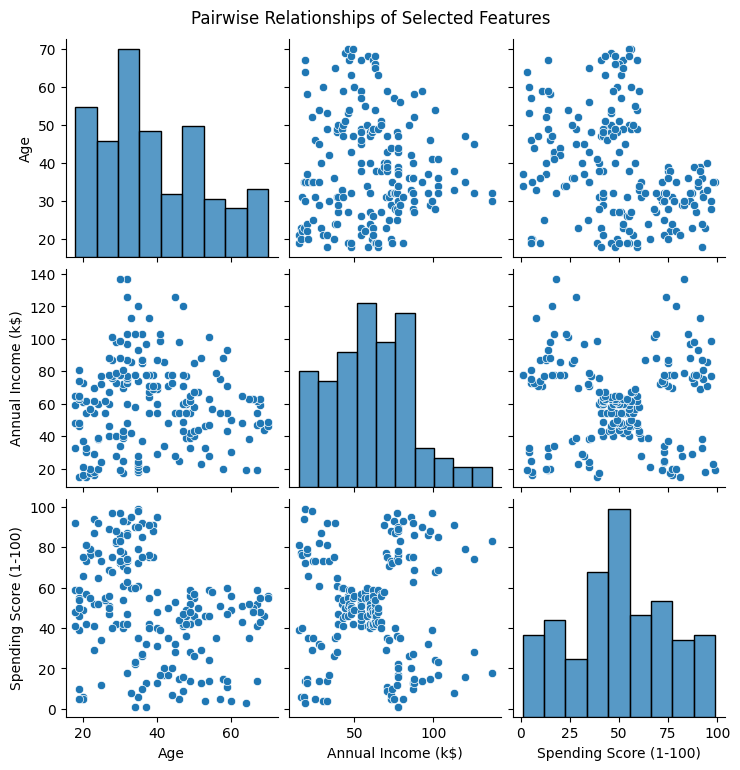

In [ ]:
# Visualize relationships between selected features

sns.pairplot(X)
plt.suptitle("Pairwise Relationships of Selected Features", y=1.02)
plt.show()

In [ ]:
# Display original and selected dataset dimensions

print("Original Dataset Shape:", df.shape)
print("Selected Dataset Shape:", X.shape)

print("\nRemoved Columns: CustomerID and Gender")
print("Selected Columns:", X.columns.tolist())

Original Dataset Shape: (200, 5)
Selected Dataset Shape: (200, 3)

Removed Columns: CustomerID and Gender
Selected Columns: ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']


In [ ]:
# Apply feature scaling

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Feature scaling completed successfully!")

print("\nScaled Data (First 5 Rows):")
print(X_scaled[:5])

Feature scaling completed successfully!

Scaled Data (First 5 Rows):
[[-1.42456879 -1.73899919 -0.43480148]
 [-1.28103541 -1.73899919  1.19570407]
 [-1.3528021  -1.70082976 -1.71591298]
 [-1.13750203 -1.70082976  1.04041783]
 [-0.56336851 -1.66266033 -0.39597992]]


In [ ]:
# Convert scaled data into DataFrame

X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=X.columns
)

display(X_scaled_df.head())

,Age,Annual Income (k$),Spending Score (1-100)
0,-1.424569,-1.738999,-0.434801
1,-1.281035,-1.738999,1.195704
2,-1.352802,-1.700830,-1.715913
3,-1.137502,-1.700830,1.040418
4,-0.563369,-1.662660,-0.395980


In [ ]:
# Compare original and scaled feature statistics

print("Original Feature Means:")
print(X.mean())

print("\nScaled Feature Means:")
print(X_scaled_df.mean())

print("\nOriginal Feature Standard Deviations:")
print(X.std())

print("\nScaled Feature Standard Deviations:")
print(X_scaled_df.std())

Original Feature Means:
Age                       38.85
Annual Income (k$)        60.56
Spending Score (1-100)    50.20
dtype: float64

Scaled Feature Means:
Age                      -1.021405e-16
Annual Income (k$)       -2.131628e-16
Spending Score (1-100)   -1.465494e-16
dtype: float64

Original Feature Standard Deviations:
Age                       13.969007
Annual Income (k$)        26.264721
Spending Score (1-100)    25.823522
dtype: float64

Scaled Feature Standard Deviations:
Age                       1.002509
Annual Income (k$)        1.002509
Spending Score (1-100)    1.002509
dtype: float64


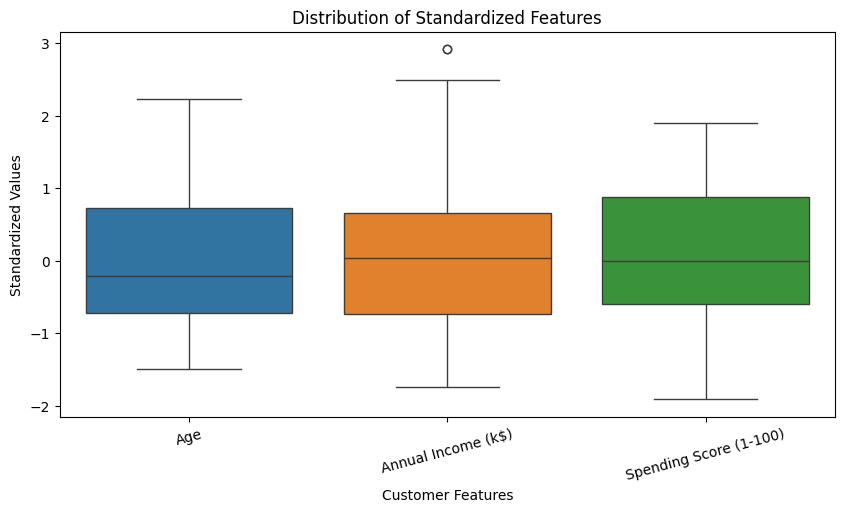

In [ ]:
# Visualize scaled features

plt.figure(figsize=(10, 5))

sns.boxplot(data=X_scaled_df)

plt.title("Distribution of Standardized Features")
plt.xlabel("Customer Features")
plt.ylabel("Standardized Values")

plt.xticks(rotation=15)
plt.show()

In [ ]:
# Calculate WCSS for different numbers of clusters

wcss = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++',
                    random_state=42, n_init=10)

    kmeans.fit(X_scaled)

    wcss.append(kmeans.inertia_)

print("WCSS Values:")
for i, value in enumerate(wcss, start=1):
    print(f"Clusters: {i}, WCSS: {value:.2f}")

WCSS Values:
Clusters: 1, WCSS: 600.00
Clusters: 2, WCSS: 389.39
Clusters: 3, WCSS: 295.21
Clusters: 4, WCSS: 205.23
Clusters: 5, WCSS: 168.25
Clusters: 6, WCSS: 133.87
Clusters: 7, WCSS: 117.01
Clusters: 8, WCSS: 103.87
Clusters: 9, WCSS: 93.09
Clusters: 10, WCSS: 82.39


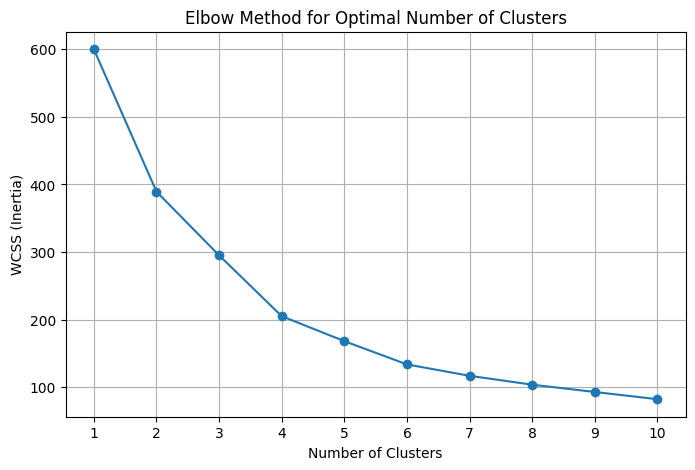

In [ ]:
# Plot the Elbow Method graph

plt.figure(figsize=(8, 5))

plt.plot(range(1, 11), wcss, marker='o')

plt.title('Elbow Method for Optimal Number of Clusters')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS (Inertia)')

plt.xticks(range(1, 11))
plt.grid(True)

plt.show()

In [ ]:
# Apply K-Means Clustering

kmeans = KMeans(
    n_clusters=5,
    init='k-means++',
    random_state=42,
    n_init=10
)

# Train the model
y_kmeans = kmeans.fit_predict(X_scaled)

# Add cluster labels to the dataset
df['Cluster'] = y_kmeans

print("K-Means Clustering Applied Successfully!")

K-Means Clustering Applied Successfully!


In [ ]:
# Display customer records with cluster labels

display(df.head(10))

print("\nCluster Distribution:")
print(df['Cluster'].value_counts().sort_index())

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,1
1,2,Male,21,15,81,1
2,3,Female,20,16,6,0
3,4,Female,23,16,77,1
4,5,Female,31,17,40,1
5,6,Female,22,17,76,1
6,7,Female,35,18,6,0
7,8,Female,23,18,94,1
8,9,Male,64,19,3,0
9,10,Female,30,19,72,1



Cluster Distribution:
Cluster
0    20
1    54
2    40
3    39
4    47
Name: count, dtype: int64


In [ ]:
# Calculate the number of customers in each cluster

cluster_counts = df['Cluster'].value_counts().sort_index()

print("Number of Customers in Each Cluster:")
print(cluster_counts)

print("\nPercentage of Customers in Each Cluster:")
print((cluster_counts / len(df) * 100).round(2))

Number of Customers in Each Cluster:
Cluster
0    20
1    54
2    40
3    39
4    47
Name: count, dtype: int64

Percentage of Customers in Each Cluster:
Cluster
0    10.0
1    27.0
2    20.0
3    19.5
4    23.5
Name: count, dtype: float64


In [ ]:
# Calculate Silhouette Score

score = silhouette_score(X_scaled, y_kmeans)

print("Silhouette Score:", round(score, 4))

Silhouette Score: 0.4166


In [ ]:
# Calculate the number of customers in each cluster

cluster_counts = df['Cluster'].value_counts().sort_index()

print("Number of Customers in Each Cluster:")
print(cluster_counts)

print("\nPercentage of Customers in Each Cluster:")
print((cluster_counts / len(df) * 100).round(2))

Number of Customers in Each Cluster:
Cluster
0    20
1    54
2    40
3    39
4    47
Name: count, dtype: int64

Percentage of Customers in Each Cluster:
Cluster
0    10.0
1    27.0
2    20.0
3    19.5
4    23.5
Name: count, dtype: float64


In [ ]:
# Calculate Silhouette Score

score = silhouette_score(X_scaled, y_kmeans)

print("Silhouette Score:", round(score, 4))

Silhouette Score: 0.4166


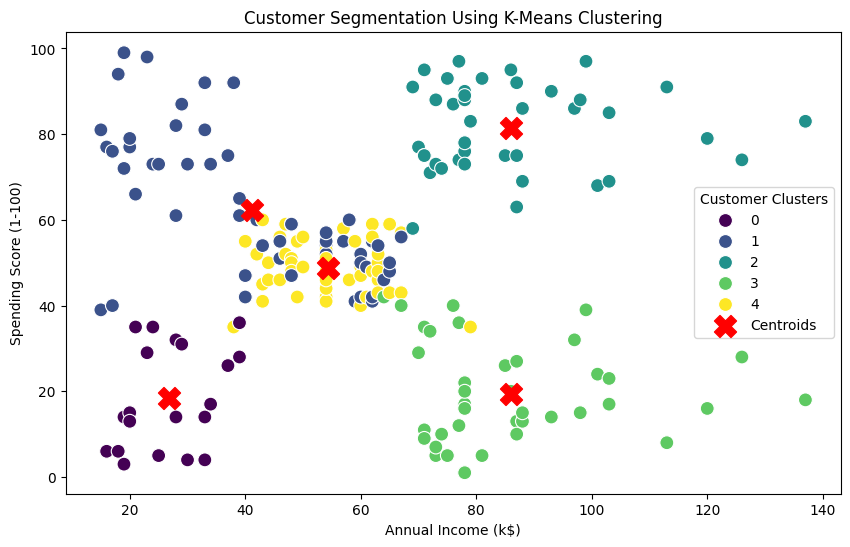

In [ ]:
# Visualize customer clusters

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Cluster',
    palette='viridis',
    s=100
)

# Convert scaled centroids back to original values
centers = scaler.inverse_transform(kmeans.cluster_centers_)

plt.scatter(
    centers[:, 1],
    centers[:, 2],
    s=250,
    marker='X',
    color='red',
    label='Centroids'
)

plt.title('Customer Segmentation Using K-Means Clustering')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend(title='Customer Clusters')
plt.show()

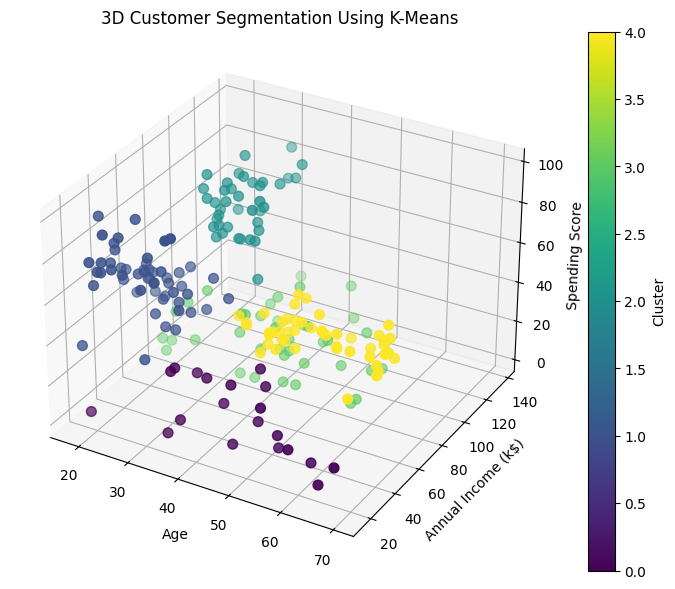

In [ ]:
# 3D visualization of customer clusters

fig = plt.figure(figsize=(10, 7))

ax = fig.add_subplot(111, projection='3d')

scatter = ax.scatter(
    df['Age'],
    df['Annual Income (k$)'],
    df['Spending Score (1-100)'],
    c=df['Cluster'],
    cmap='viridis',
    s=50
)

ax.set_title('3D Customer Segmentation Using K-Means')
ax.set_xlabel('Age')
ax.set_ylabel('Annual Income (k$)')
ax.set_zlabel('Spending Score')

plt.colorbar(scatter, label='Cluster')
plt.show()

In [ ]:
# Analyze characteristics of each cluster

cluster_analysis = df.groupby('Cluster').agg({
    'Age': 'mean',
    'Annual Income (k$)': 'mean',
    'Spending Score (1-100)': 'mean',
    'CustomerID': 'count'
}).round(2)

cluster_analysis.rename(
    columns={'CustomerID': 'Number of Customers'},
    inplace=True
)

print("Detailed Cluster Analysis:")
display(cluster_analysis)

Detailed Cluster Analysis:


,Age,Annual Income (k$),Spending Score (1-100),Number of Customers
Cluster,,,,
0,46.25,26.75,18.35,20
1,25.19,41.09,62.24,54
2,32.88,86.10,81.53,40
3,39.87,86.10,19.36,39
4,55.64,54.38,48.85,47


In [ ]:
# Calculate customer percentage in each cluster

cluster_percentage = (
    df['Cluster'].value_counts(normalize=True)
    .sort_index() * 100
)

print("Customer Percentage in Each Cluster:")
print(cluster_percentage.round(2))

Customer Percentage in Each Cluster:
Cluster
0    10.0
1    27.0
2    20.0
3    19.5
4    23.5
Name: proportion, dtype: float64


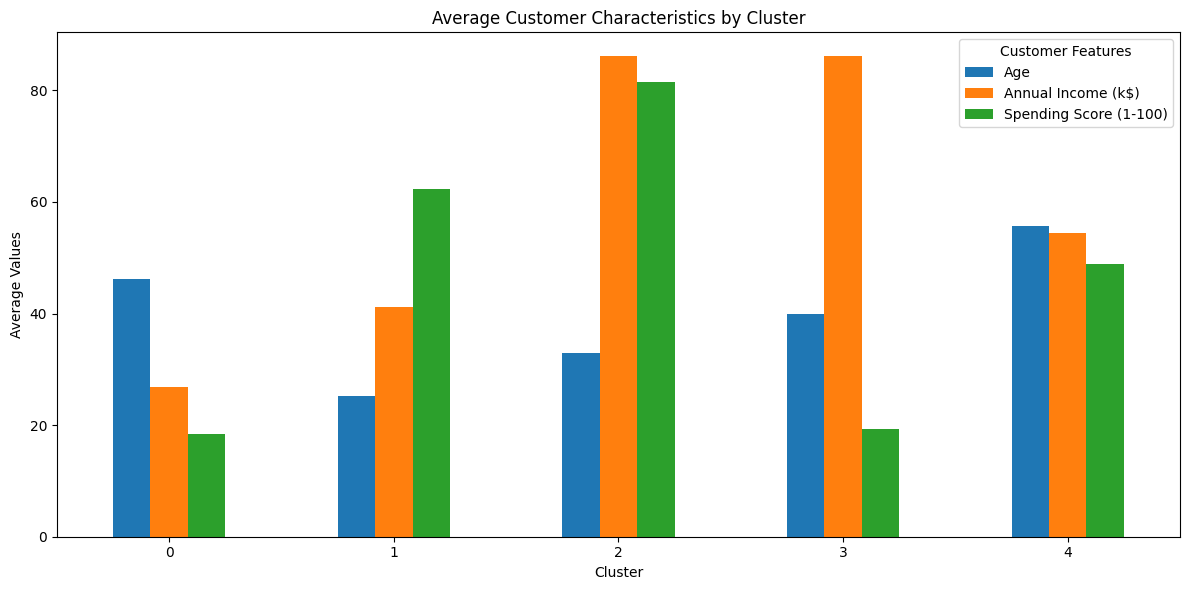

In [ ]:
# Visualize average characteristics of each cluster

cluster_analysis[
    ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
].plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Average Customer Characteristics by Cluster')
plt.xlabel('Cluster')
plt.ylabel('Average Values')
plt.xticks(rotation=0)
plt.legend(title='Customer Features')
plt.tight_layout()
plt.show()

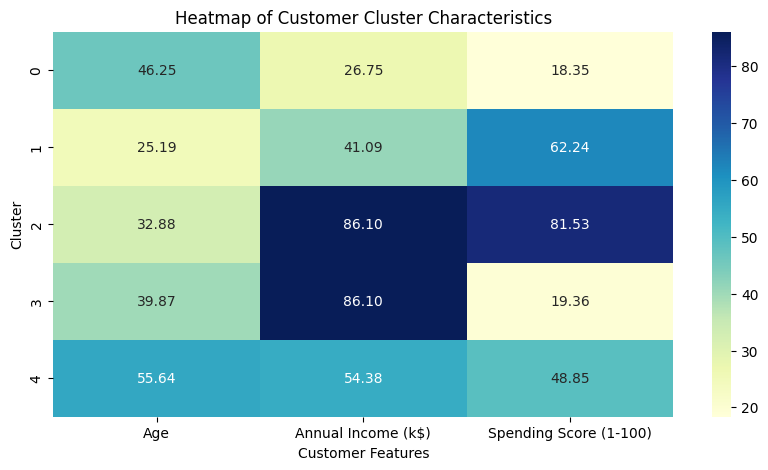

In [ ]:
# Heatmap of average cluster characteristics

plt.figure(figsize=(10, 5))

sns.heatmap(
    cluster_analysis[
        ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
    ],
    annot=True,
    cmap='YlGnBu',
    fmt='.2f'
)

plt.title('Heatmap of Customer Cluster Characteristics')
plt.xlabel('Customer Features')
plt.ylabel('Cluster')

plt.show()

In [ ]:
# Evaluate clustering using Silhouette Score

sil_score = silhouette_score(X_scaled, y_kmeans)

print("Clustering Evaluation")
print("-----------------------------")
print("Silhouette Score:", round(sil_score, 4))

Clustering Evaluation
-----------------------------
Silhouette Score: 0.4166


In [ ]:
# Display WCSS value

print("WCSS (Inertia):", round(kmeans.inertia_, 2))

WCSS (Inertia): 168.25


In [ ]:
from sklearn.metrics import davies_bouldin_score

# Calculate Davies-Bouldin Index

db_score = davies_bouldin_score(X_scaled, y_kmeans)

print("Davies-Bouldin Score:", round(db_score, 4))

Davies-Bouldin Score: 0.8746


In [ ]:
# Final clustering evaluation summary

print("FINAL CLUSTERING EVALUATION")
print("============================")

print("Number of Clusters:", kmeans.n_clusters)
print("Total Customers:", len(df))
print("WCSS:", round(kmeans.inertia_, 2))
print("Silhouette Score:", round(sil_score, 4))
print("Davies-Bouldin Score:", round(db_score, 4))

FINAL CLUSTERING EVALUATION
Number of Clusters: 5
Total Customers: 200
WCSS: 168.25
Silhouette Score: 0.4166
Davies-Bouldin Score: 0.8746


In [ ]:
# Generate customer segment summary

for cluster in sorted(df['Cluster'].unique()):

    segment = df[df['Cluster'] == cluster]

    print(f"\nCUSTOMER CLUSTER {cluster}")
    print("----------------------------")

    print("Total Customers:", len(segment))
    print("Average Age:", round(segment['Age'].mean(), 2))
    print("Average Income:",
          round(segment['Annual Income (k$)'].mean(), 2))
    print("Average Spending Score:",
          round(segment['Spending Score (1-100)'].mean(), 2))


CUSTOMER CLUSTER 0
----------------------------
Total Customers: 20
Average Age: 46.25
Average Income: 26.75
Average Spending Score: 18.35

CUSTOMER CLUSTER 1
----------------------------
Total Customers: 54
Average Age: 25.19
Average Income: 41.09
Average Spending Score: 62.24

CUSTOMER CLUSTER 2
----------------------------
Total Customers: 40
Average Age: 32.88
Average Income: 86.1
Average Spending Score: 81.53

CUSTOMER CLUSTER 3
----------------------------
Total Customers: 39
Average Age: 39.87
Average Income: 86.1
Average Spending Score: 19.36

CUSTOMER CLUSTER 4
----------------------------
Total Customers: 47
Average Age: 55.64
Average Income: 54.38
Average Spending Score: 48.85


In [ ]:
# Business strategies for different customer groups

business_strategies = {
    0: "Provide personalized offers and loyalty rewards.",
    1: "Promote affordable products and discounts.",
    2: "Introduce premium products and exclusive offers.",
    3: "Use targeted marketing to increase customer spending.",
    4: "Focus on customer retention and personalized recommendations."
}

print("BUSINESS RECOMMENDATIONS\n")

for cluster, strategy in business_strategies.items():
    print(f"Cluster {cluster}: {strategy}")

BUSINESS RECOMMENDATIONS

Cluster 0: Provide personalized offers and loyalty rewards.
Cluster 1: Promote affordable products and discounts.
Cluster 2: Introduce premium products and exclusive offers.
Cluster 3: Use targeted marketing to increase customer spending.
Cluster 4: Focus on customer retention and personalized recommendations.


In [ ]:
# Save the final clustered dataset

df.to_csv('Customer_Segmentation_Results.csv', index=False)

print("Clustered dataset saved successfully!")

Clustered dataset saved successfully!


In [ ]:
# Verify the saved dataset

import os

print("Saved File:", os.path.exists('Customer_Segmentation_Results.csv'))

print("\nFinal Dataset Shape:", df.shape)

print("\nFinal Dataset Preview:")
display(df.head(10))

Saved File: True

Final Dataset Shape: (200, 6)

Final Dataset Preview:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,1
1,2,Male,21,15,81,1
2,3,Female,20,16,6,0
3,4,Female,23,16,77,1
4,5,Female,31,17,40,1
5,6,Female,22,17,76,1
6,7,Female,35,18,6,0
7,8,Female,23,18,94,1
8,9,Male,64,19,3,0
9,10,Female,30,19,72,1


In [ ]:
from google.colab import files

files.download('Customer_Segmentation_Results.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Final Results Summary

print("CUSTOMER SEGMENTATION - FINAL RESULTS")
print("=" * 45)

print("Total Customers:", len(df))
print("Total Features Used:", X.shape[1])
print("Clustering Algorithm: K-Means")
print("Number of Clusters:", kmeans.n_clusters)

print("\nCLUSTER DISTRIBUTION")
print("-" * 45)

for cluster, count in df['Cluster'].value_counts().sort_index().items():
    percentage = (count / len(df)) * 100
    print(f"Cluster {cluster}: {count} customers ({percentage:.2f}%)")

print("\nMODEL EVALUATION")
print("-" * 45)

print("WCSS:", round(kmeans.inertia_, 2))
print("Silhouette Score:", round(sil_score, 4))
print("Davies-Bouldin Score:", round(db_score, 4))

CUSTOMER SEGMENTATION - FINAL RESULTS
Total Customers: 200
Total Features Used: 3
Clustering Algorithm: K-Means
Number of Clusters: 5

CLUSTER DISTRIBUTION
---------------------------------------------
Cluster 0: 20 customers (10.00%)
Cluster 1: 54 customers (27.00%)
Cluster 2: 40 customers (20.00%)
Cluster 3: 39 customers (19.50%)
Cluster 4: 47 customers (23.50%)

MODEL EVALUATION
---------------------------------------------
WCSS: 168.25
Silhouette Score: 0.4166
Davies-Bouldin Score: 0.8746


In [ ]:
# Final cluster comparison

final_comparison = df.groupby('Cluster').agg(
    Customer_Count=('CustomerID', 'count'),
    Average_Age=('Age', 'mean'),
    Average_Income=('Annual Income (k$)', 'mean'),
    Average_Spending=('Spending Score (1-100)', 'mean')
).round(2)

final_comparison['Percentage'] = (
    final_comparison['Customer_Count'] / len(df) * 100
).round(2)

display(final_comparison)

,Customer_Count,Average_Age,Average_Income,Average_Spending,Percentage
Cluster,,,,,
0,20,46.25,26.75,18.35,10.0
1,54,25.19,41.09,62.24,27.0
2,40,32.88,86.10,81.53,20.0
3,39,39.87,86.10,19.36,19.5
4,47,55.64,54.38,48.85,23.5


In [ ]:
# Export cluster comparison table

final_comparison.to_csv('Cluster_Analysis_Summary.csv')

print("Cluster analysis summary saved successfully!")

Cluster analysis summary saved successfully!


In [ ]:
# Display final cluster analysis

display(final_comparison)

print("\nSilhouette Score:", round(sil_score, 4))
print("WCSS:", round(kmeans.inertia_, 2))
print("Davies-Bouldin Score:", round(db_score, 4))

,Customer_Count,Average_Age,Average_Income,Average_Spending,Percentage
Cluster,,,,,
0,20,46.25,26.75,18.35,10.0
1,54,25.19,41.09,62.24,27.0
2,40,32.88,86.10,81.53,20.0
3,39,39.87,86.10,19.36,19.5
4,47,55.64,54.38,48.85,23.5



Silhouette Score: 0.4166
WCSS: 168.25
Davies-Bouldin Score: 0.8746


Final Results and Cluster Interpretation

The K-Means clustering algorithm successfully divided 200 customers into five distinct clusters based on their age, annual income, and spending score.

The analysis identified five customer segments:
1. Cluster 0: Low-income, low-spending customers.
2. Cluster 1: Young customers with moderate income and high spending.
3. Cluster 2: High-income, high-spending customers.
4. Cluster 3: High-income, low-spending customers.
5. Cluster 4: Older customers with moderate income and moderate spending.
The model achieved a Silhouette Score of 0.4166, WCSS of 168.25, and Davies-Bouldin Score of 0.8746.

These results demonstrate that K-Means clustering can help businesses understand customer behaviour and develop targeted marketing strategies.